# Analysis of MPs Expenses
An analysis of MP's expenses.

Actions taken:
- aligned all budget column naming conventions
- 10/11, 11/12, 12/13 do not hold any budget data. Can only evualate spend trend
- Outliers may be data quality issues or signs of genuine overspend.

In [17]:
## Libraries

from pathlib import Path
import pandas as pd
import numpy as np

In [ ]:
data_dir = Path(r"C:\Users\mattc\OneDrive\Documents\git repos\GIAA-Data-Analytics-Speciailist\Raw Data")

def standardise_columns(df):
    df.columns = (df.columns
        .str.replace("\ufeff", "", regex=False)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.replace("Wind-up", "Winding-up", regex=False)
        .str.replace("wind-up", "winding-up", regex=False)
        .str.replace(" maximum budget available", " budget", regex=False))

    # 24/25 splits constituency into two columns
    new = "Constituency since 5 July 2024"
    if "Constituency" not in df.columns and new in df.columns:
        df["Constituency"] = df[new]
        if "Previous constituency" in df.columns:
            df["Constituency"] = df["Constituency"].fillna(df["Previous constituency"])

    # Drop the repeated "Reason for budget set", "Reason for budget set.1", etc.
    df = df.loc[:, ~df.columns.str.startswith("Reason for budget set")]

    dupes = df.columns[df.columns.duplicated()].tolist()
    if dupes:
        print("Duplicate columns after renaming:", dupes)
    return df


def load_series(prefix, folder=data_dir, **read_csv_kwargs):
    read_csv_kwargs.setdefault("encoding", "utf-8-sig")
    files = sorted(folder.glob(f"{prefix}_*_*.csv"))
    if not files:
        raise FileNotFoundError(f"No files found for {prefix} in {folder}")

    frames = []
    for f in files:
        x, y = f.stem.split("_")[-2:]
        df = standardise_columns(pd.read_csv(f, **read_csv_kwargs))
        df["financial_year"] = f"{x}/{y}"
        frames.append(df)

    base_cols = set(frames[0].columns)
    for f, df in zip(files, frames):
        diff = set(df.columns) ^ base_cols
        if diff:
            print(f"{prefix}: {f.name} column differences -> {diff}")

    return pd.concat(frames, ignore_index=True)


spend = load_series("totalSpend")

budget_cols = [c for c in spend.columns
               if c.endswith(" budget") and not c.startswith("Remaining")]
print(spend.groupby("financial_year")[budget_cols].count())
print(spend.groupby("financial_year")["Constituency"].apply(lambda s: s.notna().sum()))

totalSpend: totalSpend_11_12.csv column differences -> {'Start-up spend', 'Remaining start-up budget', 'Office budget', 'Start-up budget'}
totalSpend: totalSpend_12_13.csv column differences -> {'Start-up spend', 'Remaining start-up budget', 'Start-up budget'}
totalSpend: totalSpend_13_14.csv column differences -> {'Start-up spend', 'Remaining start-up budget', 'Start-up budget'}
totalSpend: totalSpend_14_15.csv column differences -> {'Start-up spend', 'Remaining start-up budget', 'Start-up budget'}
totalSpend: totalSpend_15_16.csv column differences -> {'Start-up spend', 'Remaining start-up budget', 'Start-up budget'}
totalSpend: totalSpend_16_17.csv column differences -> {'Start-up spend', 'Remaining start-up budget', 'Start-up budget'}
totalSpend: totalSpend_22_23.csv column differences -> {'Travel and subsistence budget', 'Travel and subsistence spend', 'Other costs spend', 'Other costs (uncapped)', 'Travel and subsistence (uncapped)', 'Overall total spend for this financial year',

In [19]:
#### Ideas
# Need to review the new columns that appear
# Percentage of budgets used by each constituency
# Any outliers/any values that don't reconcile (i.e >100% of budget spent)
# Data quality
# Are MPs abiding by principles


## Total Spend Analysis

In [22]:
# Group the types of budget and strip unwanted £ symbols.
# budgets = ["Office", "Staffing", "Winding-up", "Accommodation", "Start-up"]
budgets = [b for b in budgets if f"{b} budget" in spend.columns and f"{b} spend" in spend.columns]
money_cols = [f"{b} {kind}" for b in budgets for kind in ("budget", "spend")]
money_cols = [c.replace("Office budget", "Office budget") for c in money_cols]  # names match your columns

for c in money_cols:
    spend[c] = pd.to_numeric(
        spend[c].astype(str).str.replace(r"[£,]", "", regex=True),
        errors="coerce",
    )

# Total Budget
# Find percentage spend to capture larger budget sizes.
# How to handle more than one MP in a given year?

rows = []
for b in budgets:
    g = (spend.groupby(["Constituency", "financial_year"])
              [[f"{b} budget", f"{b} spend"]].sum()
              .rename(columns={f"{b} budget": "budget", f"{b} spend": "spend"})
              .reset_index())
    g["budget_type"] = b
    rows.append(g)

usage = pd.concat(rows, ignore_index=True)
usage["pct_spent"] = (usage["spend"] / usage["budget"]).where(usage["budget"] > 0) * 100

usage

,Constituency,financial_year,budget,spend,budget_type,pct_spent
0,Aberafan Maesteg CC,24/25,33020.00,27261.39,Office,82.560236
1,Aberavon CC,10/11,0.00,28036.37,Office,NaN
2,Aberavon CC,11/12,0.00,17950.21,Office,NaN
3,Aberavon CC,12/13,0.00,21309.83,Office,NaN
4,Aberavon CC,13/14,22750.00,22014.70,Office,96.767912
...,...,...,...,...,...,...
39531,York Outer CC,20/21,4822.12,4822.12,Accommodation,100.000000
39532,York Outer CC,21/22,9656.52,9656.52,Accommodation,100.000000
39533,York Outer CC,22/23,30800.00,12245.97,Accommodation,39.759643
39534,York Outer CC,23/24,32960.00,12702.37,Accommodation,38.538744


In [24]:
# Outliers
usage_overspend_outliers = (
    usage[(usage["budget"] > 0) & (usage["pct_spent"] > 100)]
    .assign(overspend=lambda d: d["spend"] - d["budget"])
    .sort_values("pct_spent", ascending=False)
    .reset_index(drop=True)
)

usage_overspend_outliers = usage_overspend_outliers[
    ["Constituency", "financial_year", "budget_type",
     "budget", "spend", "overspend", "pct_spent"]
]

usage_overspend_outliers

,Constituency,financial_year,budget_type,budget,spend,overspend,pct_spent
0,Bradford West BC,12/13,Staffing,16090.30,117426.000,101335.700,729.793727
1,Leicester South BC,12/13,Accommodation,8850.00,22805.290,13955.290,257.686893
2,North Antrim CC,14/15,Office,16617.32,25723.500,9106.180,154.799330
3,Central Suffolk and North Ipswich CC,13/14,Accommodation,13680.00,19247.380,5567.380,140.697222
4,Morecambe and Lunesdale CC,14/15,Office,17092.26,22183.900,5091.640,129.789156
...,...,...,...,...,...,...,...
224,Hackney North and Stoke Newington BC,17/18,Office,26850.00,26850.004,0.004,100.000015
225,Neath CC,14/15,Staffing,137257.54,137257.560,0.020,100.000015
226,"Cumbernauld, Kilsyth and Kirkintilloch East CC",17/18,Office,24150.00,24150.002,0.002,100.000008
227,Hove BC,17/18,Office,24150.00,24150.002,0.002,100.000008


In [ ]:
####### Histogram

# import numpy as np
# import matplotlib.pyplot as plt

# # remove outliers
# keys = ["Constituency", "financial_year", "budget_type"]

# usage_clean = (
#     usage.merge(usage_overspend_outliers[keys].drop_duplicates(),
#                 on=keys, how="left", indicator=True)
#          .query("_merge == 'left_only'")
#          .drop(columns="_merge")
# )

# def plot_usage_hist(usage, budget_type, max_pct=120, ncols=4):
#     d = usage[(usage["budget_type"] == budget_type) & usage["pct_spent"].notna()]
#     years = sorted(d["financial_year"].unique())
#     nrows = -(-len(years) // ncols)          # ceiling division
#     bins = np.arange(0, max_pct + 1, 1)      # 1% buckets

#     fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows),
#                              sharex=True, sharey=True)
#     axes = np.atleast_1d(axes).ravel()

#     for ax, yr in zip(axes, years):
#         vals = d.loc[d["financial_year"] == yr, "pct_spent"]
#         ax.hist(vals, bins=bins, edgecolor="white", linewidth=0.3)
#         ax.set_xlim(0, 100)
#         ax.set_xticks(range(0, 101, 20))
#         ax.set_title(f"{yr} (n={len(vals)})", fontsize=10)

#     for ax in axes[len(years):]:             # hide unused panels
#         ax.set_visible(False)

#     fig.suptitle(f"{budget_type} budget: % spent by constituency", y=1.0, fontsize=14)
#     fig.supxlabel("% of budget spent (1% buckets)")
#     fig.supylabel("Number of constituencies")
#     fig.tight_layout()
#     plt.show()

# plot_usage_hist(usage_clean, "Staffing")

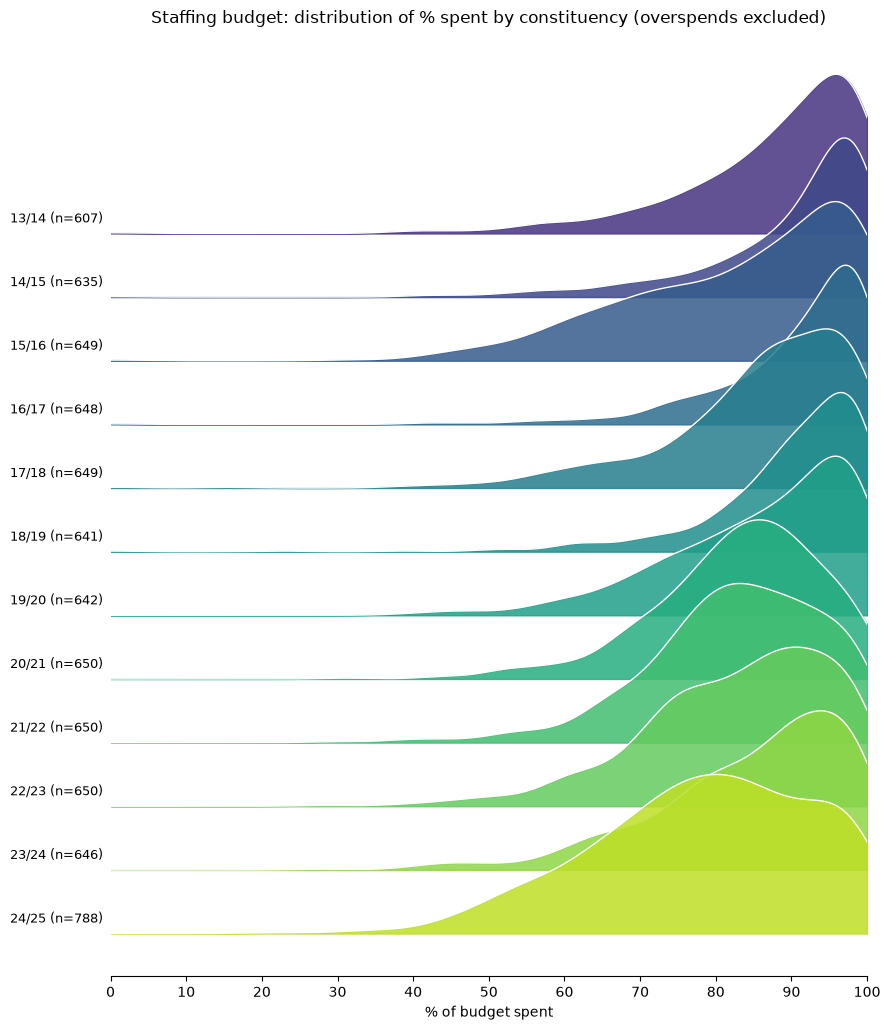

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

def plot_usage_ridge(usage, budget_type, overlap=0.6, bw=0.3, cmap="viridis"):
    d = usage[(usage["budget_type"] == budget_type) & usage["pct_spent"].notna()]
    years = sorted(d["financial_year"].unique())
    x = np.linspace(0, 100, 500)
    colours = plt.get_cmap(cmap)(np.linspace(0.15, 0.9, len(years)))

    fig, ax = plt.subplots(figsize=(9, 0.7 * len(years) + 2))

    for i, (yr, col) in enumerate(zip(years, colours)):
        vals = d.loc[d["financial_year"] == yr, "pct_spent"].to_numpy()
        if len(vals) < 5 or np.std(vals) == 0:      # KDE needs some spread
            continue
        dens = gaussian_kde(vals, bw_method=bw)(x)
        dens = dens / dens.max()                    # scale each ridge to same height
        offset = (len(years) - i) * (1 - overlap)   # oldest year at the top
        ax.fill_between(x, offset, offset + dens, color=col, alpha=0.85, zorder=i + 2)
        ax.plot(x, offset + dens, color="white", linewidth=1, zorder=i + 2)
        ax.text(-1, offset + 0.05, f"{yr} (n={len(vals)})", ha="right", va="bottom", fontsize=9)

    ax.set_xlim(0, 100)
    ax.set_xticks(range(0, 101, 10))
    ax.set_yticks([])
    for s in ("left", "right", "top"):
        ax.spines[s].set_visible(False)
    ax.set_xlabel("% of budget spent")
    ax.set_title(f"{budget_type} budget: distribution of % spent by constituency "
                 "(overspends excluded)")
    fig.tight_layout()
    plt.show()

plot_usage_ridge(usage_clean, "Staffing")

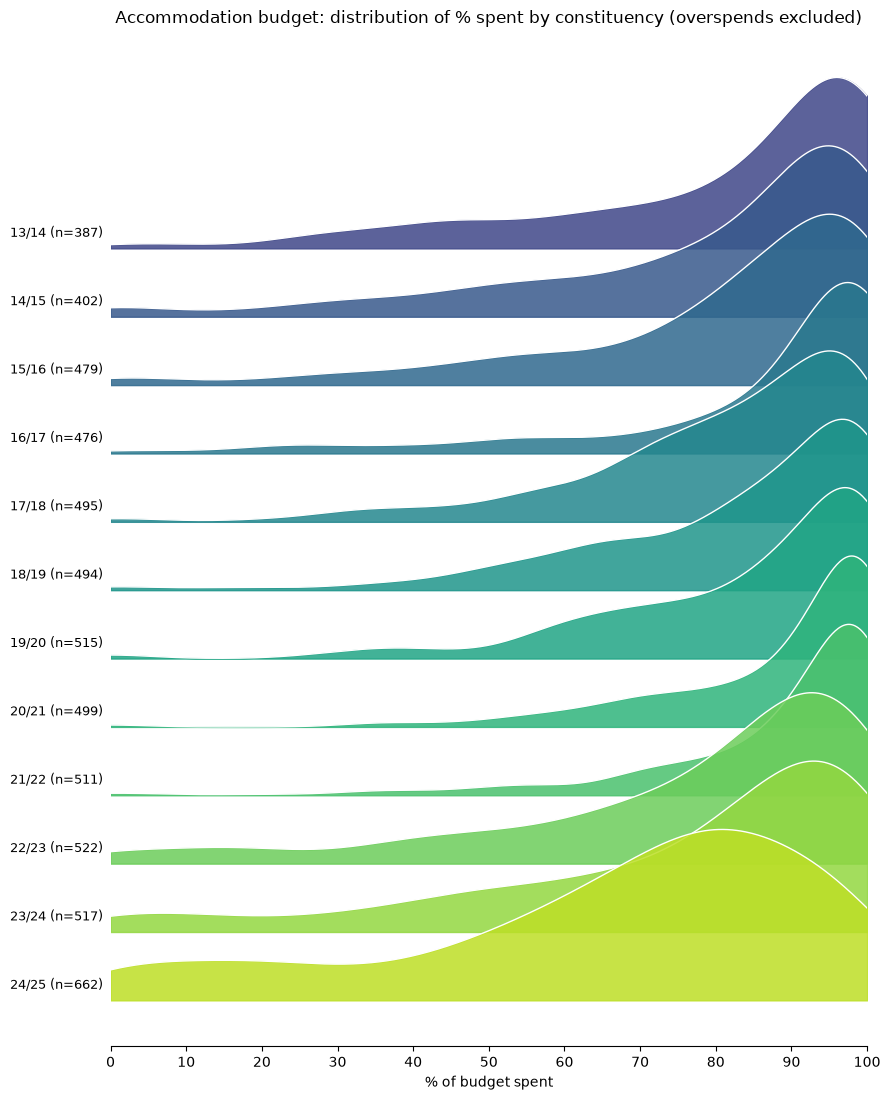

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

def plot_usage_ridge(usage, budget_type, overlap=0.6, bw=0.3, cmap="viridis"):
    d = usage[(usage["budget_type"] == budget_type) & usage["pct_spent"].notna()]
    years = sorted(d["financial_year"].unique())
    x = np.linspace(0, 100, 500)
    colours = plt.get_cmap(cmap)(np.linspace(0.15, 0.9, len(years)))

    fig, ax = plt.subplots(figsize=(9, 0.7 * len(years) + 2))

    for i, (yr, col) in enumerate(zip(years, colours)):
        vals = d.loc[d["financial_year"] == yr, "pct_spent"].to_numpy()
        if len(vals) < 5 or np.std(vals) == 0:      # KDE needs some spread
            continue
        dens = gaussian_kde(vals, bw_method=bw)(x)
        dens = dens / dens.max()                    # scale each ridge to same height
        offset = (len(years) - i) * (1 - overlap)   # oldest year at the top
        ax.fill_between(x, offset, offset + dens, color=col, alpha=0.85, zorder=i + 2)
        ax.plot(x, offset + dens, color="white", linewidth=1, zorder=i + 2)
        ax.text(-1, offset + 0.05, f"{yr} (n={len(vals)})", ha="right", va="bottom", fontsize=9)

    ax.set_xlim(0, 100)
    ax.set_xticks(range(0, 101, 10))
    ax.set_yticks([])
    for s in ("left", "right", "top"):
        ax.spines[s].set_visible(False)
    ax.set_xlabel("% of budget spent")
    ax.set_title(f"{budget_type} budget: distribution of % spent by constituency "
                 "(overspends excluded)")
    fig.tight_layout()
    plt.show()

plot_usage_ridge(usage_clean, "Accommodation")

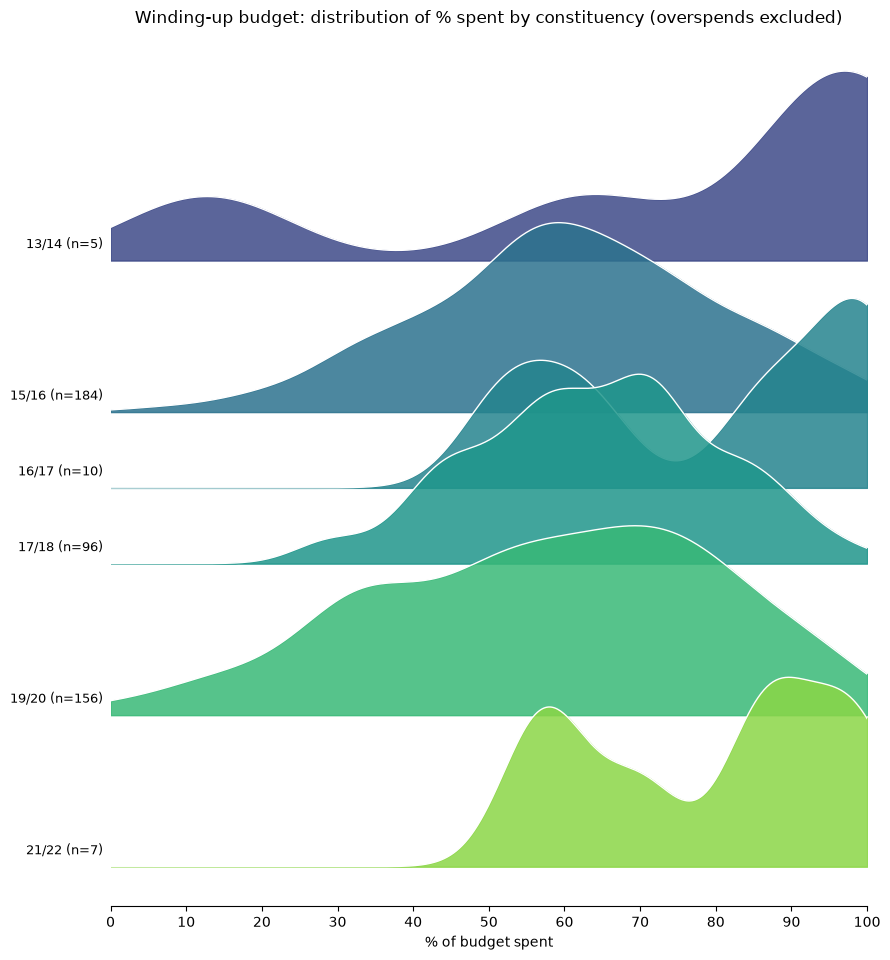

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

def plot_usage_ridge(usage, budget_type, overlap=0.6, bw=0.3, cmap="viridis"):
    d = usage[(usage["budget_type"] == budget_type) & usage["pct_spent"].notna()]
    years = sorted(d["financial_year"].unique())
    x = np.linspace(0, 100, 500)
    colours = plt.get_cmap(cmap)(np.linspace(0.15, 0.9, len(years)))

    fig, ax = plt.subplots(figsize=(9, 0.7 * len(years) + 2))

    for i, (yr, col) in enumerate(zip(years, colours)):
        vals = d.loc[d["financial_year"] == yr, "pct_spent"].to_numpy()
        if len(vals) < 5 or np.std(vals) == 0:      # KDE needs some spread
            continue
        dens = gaussian_kde(vals, bw_method=bw)(x)
        dens = dens / dens.max()                    # scale each ridge to same height
        offset = (len(years) - i) * (1 - overlap)   # oldest year at the top
        ax.fill_between(x, offset, offset + dens, color=col, alpha=0.85, zorder=i + 2)
        ax.plot(x, offset + dens, color="white", linewidth=1, zorder=i + 2)
        ax.text(-1, offset + 0.05, f"{yr} (n={len(vals)})", ha="right", va="bottom", fontsize=9)

    ax.set_xlim(0, 100)
    ax.set_xticks(range(0, 101, 10))
    ax.set_yticks([])
    for s in ("left", "right", "top"):
        ax.spines[s].set_visible(False)
    ax.set_xlabel("% of budget spent")
    ax.set_title(f"{budget_type} budget: distribution of % spent by constituency "
                 "(overspends excluded)")
    fig.tight_layout()
    plt.show()

plot_usage_ridge(usage_clean, "Winding-up")